In [21]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import missingno as msno
from data_profiling import ProfileReport

In [ ]:
DATASET = Path().cwd().parent / "data" / "diamonds.csv"
ARTIFACTS_PATH = Path().cwd().parent / "artifacts"
df = pd.read_csv(DATASET,encoding="utf-8")

In [23]:
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
(50000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    50000 non-null  float64
 1   cut      50000 non-null  object 
 2   color    50000 non-null  object 
 3   clarity  50000 non-null  object 
 4   depth    50000 non-null  float64
 5   table    50000 non-null  float64
 6   price    50000 non-null  int64  
 7   x        50000 non-null  float64
 8   y        50000 non-null  float64
 9   z        50000 non-null  float

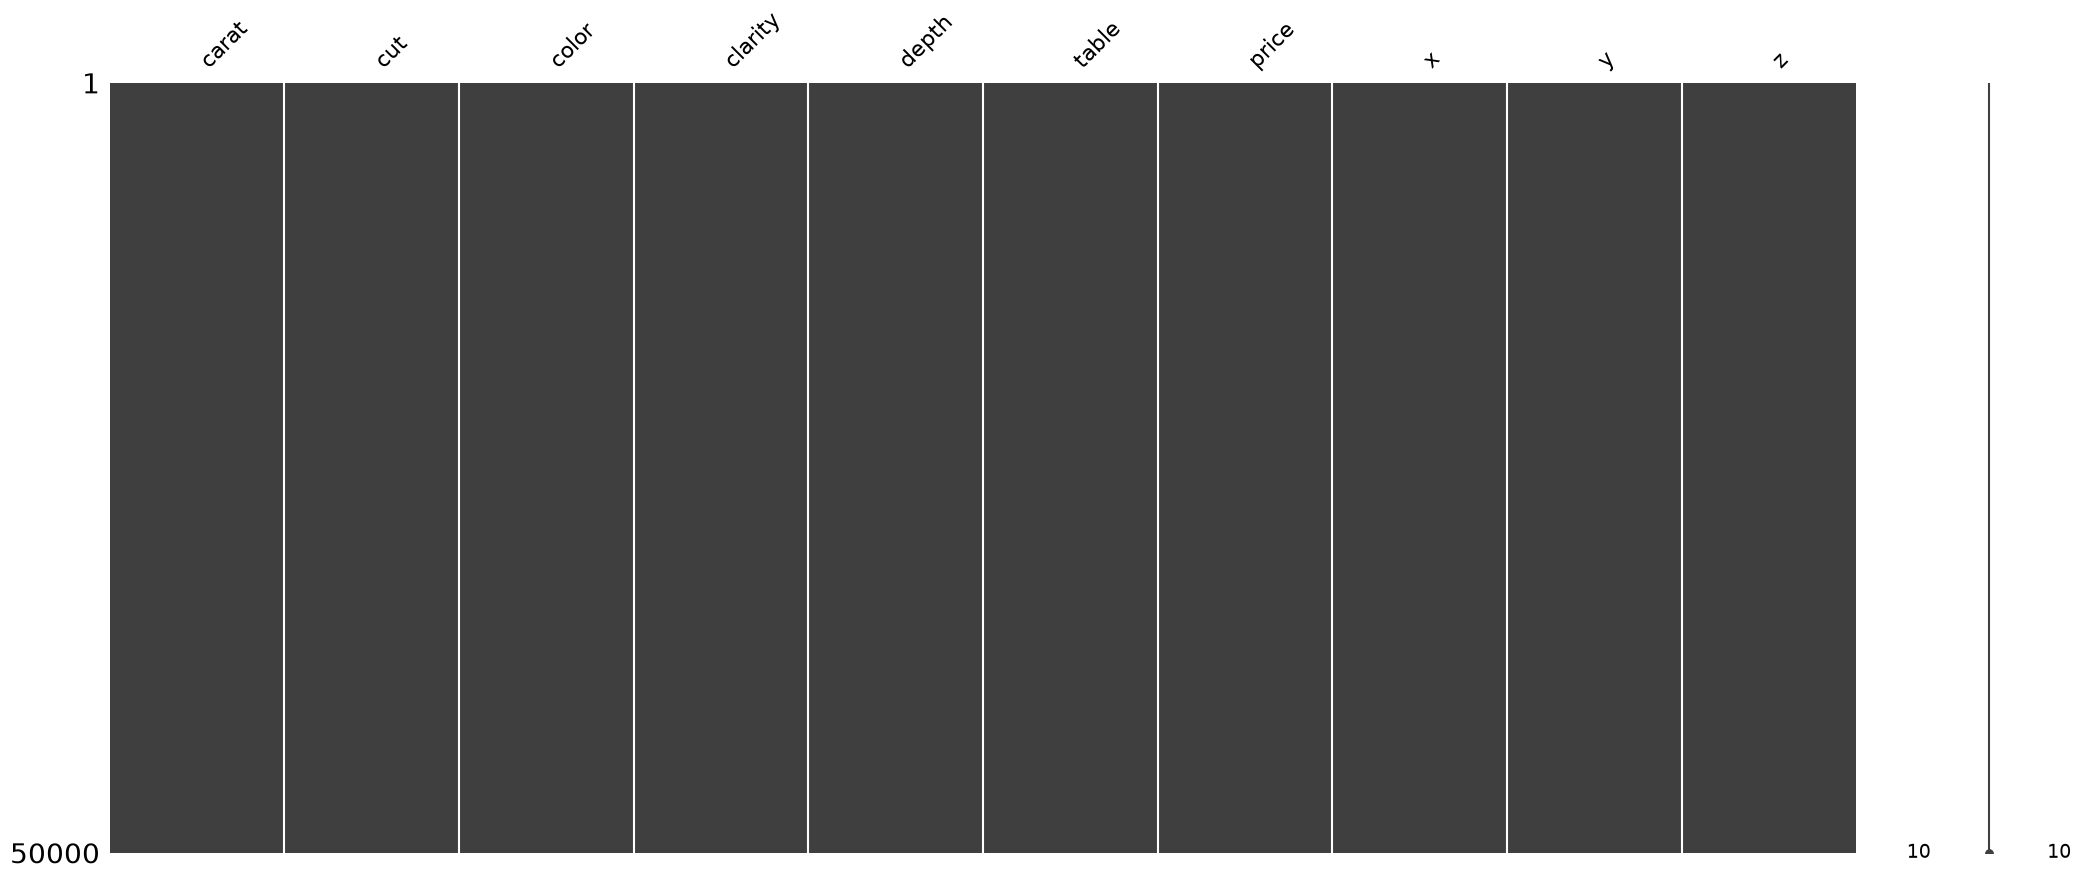

In [24]:
msno.matrix(df)
plt.savefig(Path(ARTIFACTS_PATH/"missing_values.png"),dpi=300,bbox_inches="tight")
plt.show()

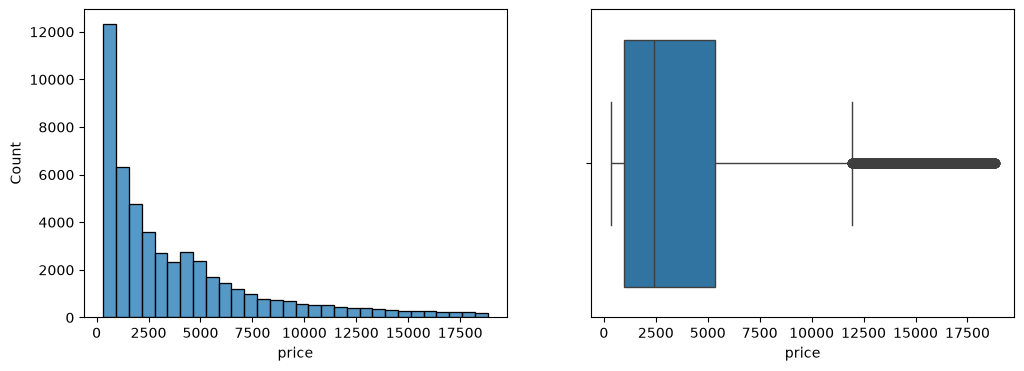

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], bins=30, ax=axes[0])
sns.boxplot(x=df['price'], ax=axes[1])
plt.savefig(ARTIFACTS_PATH / "hist_box_plot.png")
plt.show()

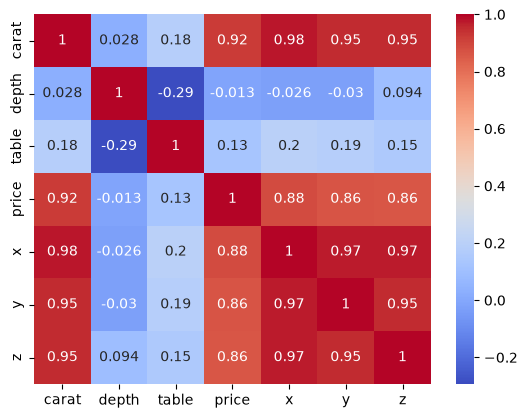

In [26]:
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.savefig(ARTIFACTS_PATH / "hetmap.png")
plt.show()

In [27]:
numeric_cols = df.select_dtypes(
    include="number"
).columns.to_list()

categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns.to_list()

print("Numerical features:", numeric_cols)
print("Categorical features:", categorical_cols)

Numerical features: ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
Categorical features: ['cut', 'color', 'clarity']


In [28]:
positive_cols = [
    col for col in ["carat", "price", "x", "y", "z"]
    if col in df.columns
]

invalid_values = (df[positive_cols] <= 0).sum()
mask = df[positive_cols]<=0
df = df[~mask] # remove the negative columns for the force positive ones

display(invalid_values)
print("\n",(df[positive_cols] <= 0).sum())

carat     0
price     0
x         7
y         6
z        17
dtype: int64


 carat    0
price    0
x        0
y        0
z        0
dtype: int64


In [29]:
REPPORT = Path().cwd().parent
profile = ProfileReport(df, title="EDA Report")
profile.to_file(REPPORT /"eda_report.html")

Export report to file: 100%|██████████| 1/1 [00:00<?, ?it/s]


In [ ]:
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (
        (df[column] < lower)
        | (df[column] > upper)
    )

    return {
        "feature": column,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": mask.sum(),
        "outlier_percentage": mask.mean() * 100
    },

In [51]:
outliers = (detect_outliers_iqr(df,col) for col in df.columns)
from pprint import pprint as p
p(list(outliers))

[{'feature': 'carat',
  'lower_bound': np.float64(-0.5599999999999999),
  'outlier_count': np.int64(1770),
  'outlier_percentage': np.float64(3.54),
  'upper_bound': np.float64(2.0)},
 {'feature': 'cut',
  'lower_bound': np.float64(nan),
  'outlier_count': np.int64(0),
  'outlier_percentage': np.float64(0.0),
  'upper_bound': np.float64(nan)},
 {'feature': 'color',
  'lower_bound': np.float64(nan),
  'outlier_count': np.int64(0),
  'outlier_percentage': np.float64(0.0),
  'upper_bound': np.float64(nan)},
 {'feature': 'clarity',
  'lower_bound': np.float64(nan),
  'outlier_count': np.int64(0),
  'outlier_percentage': np.float64(0.0),
  'upper_bound': np.float64(nan)},
 {'feature': 'depth',
  'lower_bound': np.float64(nan),
  'outlier_count': np.int64(0),
  'outlier_percentage': np.float64(0.0),
  'upper_bound': np.float64(nan)},
 {'feature': 'table',
  'lower_bound': np.float64(nan),
  'outlier_count': np.int64(0),
  'outlier_percentage': np.float64(0.0),
  'upper_bound': np.float64(nan